# Step 4: Analysis and Insights
Each analytical question from Step 1 is answered with the cleaned data. Churn rate = share of policy terms cancelled at renewal or mid-term.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW, PROC, IMG = Path('../data/raw'), Path('../data/processed'), Path('../images')
IMG.mkdir(exist_ok=True); PROC.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})
COLOR = '#2E6F95'

def save(fname):
    plt.tight_layout(); plt.savefig(IMG / fname, dpi=120); plt.show()

def load_raw():
    # EPIC_ID is built from client names: drop it on load so it never appears in any output
    terms = pd.read_excel(RAW / '1-insurance_2025_policy_terms.xlsx', sheet_name='result').drop(columns='EPIC_ID')
    demo = pd.read_excel(RAW / '2-insurance_2025_demographics.xlsx')
    return terms, demo
def bar(series, title, fname, xlabel=''):
    ax = series.plot.bar(color=COLOR, rot=0)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('Churn rate')
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
    ax.bar_label(ax.containers[0], labels=[f'{v:.1%}' for v in series], padding=2)
    save(fname)

def churn_by(df, col):
    return df.groupby(col, observed=True).agg(terms=('churned', 'size'), churn_rate=('churned', 'mean'))

In [2]:
df = pd.read_pickle(PROC / 'policy_terms_clean.pkl')
auto = pd.read_pickle(PROC / 'auto_drivers_clean.pkl')
print(f'{len(df):,} terms | {len(auto):,} auto terms with driver data')

99,999 terms | 15,354 auto terms with driver data


## 4.1 Q1: How often do policies cancel?

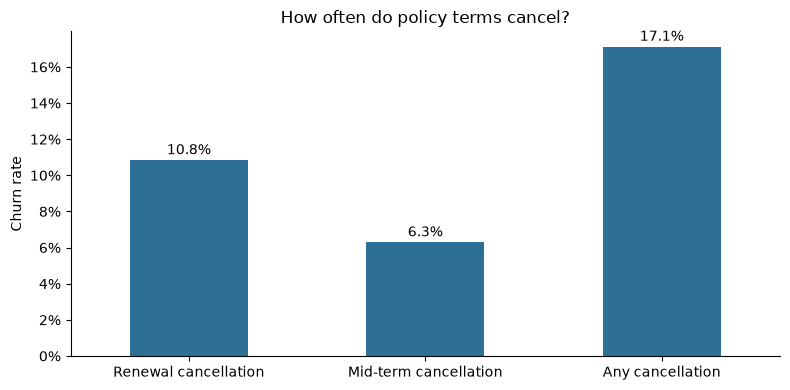

Renewal cancellation     10.8%
Mid-term cancellation     6.3%
Any cancellation         17.1%
dtype: str

In [3]:
overall = pd.Series({'Renewal cancellation': df.CAN_REN.mean(), 'Mid-term cancellation': df.CAN_MT.mean(),
                     'Any cancellation': df.churned.mean()})
bar(overall, 'How often do policy terms cancel?', '01_overall_churn.png')
overall.map('{:.1%}'.format)

## 4.2 Q2: Which lines of business cancel most?

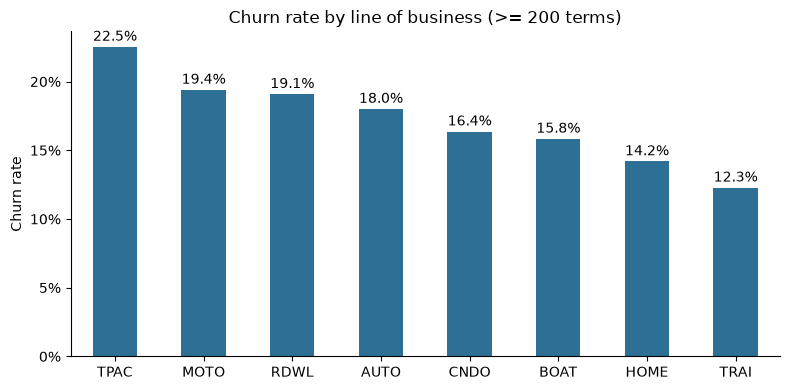

,terms,churn_rate
Line_of_Business,,
TPAC,7622,0.23
MOTO,299,0.19
RDWL,372,0.19
AUTO,57114,0.18
CNDO,4107,0.16
BOAT,240,0.16
HOME,29151,0.14
TRAI,839,0.12


In [4]:
lob = churn_by(df, 'Line_of_Business').query('terms >= 200').sort_values('churn_rate', ascending=False)
bar(lob['churn_rate'], 'Churn rate by line of business (>= 200 terms)', '02_churn_by_lob.png')
lob

## 4.3 Q3: Do bundled clients stay longer?

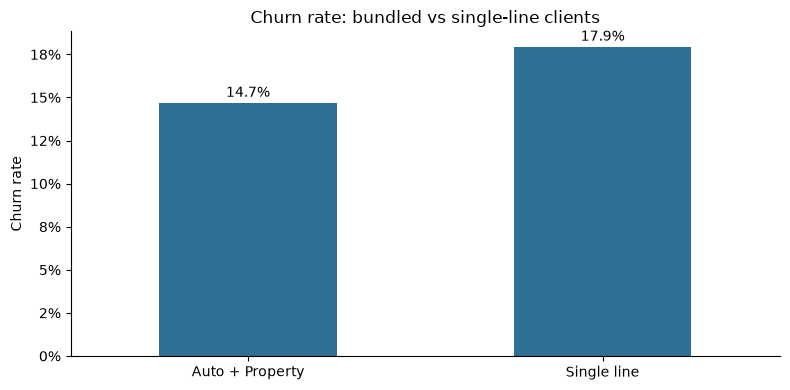

,terms,churn_rate
bundled,,
Auto + Property,25369,0.15
Single line,74630,0.18


In [5]:
bundle = churn_by(df, 'bundled')
bar(bundle['churn_rate'], 'Churn rate: bundled vs single-line clients', '03_bundled.png')
bundle

In [6]:
# check the bundling effect holds inside each product group, not just because of product mix
df.pivot_table(index='LOB_Group', columns='bundled', values='churned', aggfunc='mean').style.format('{:.1%}')

bundled,Auto + Property,Single line
LOB_Group,,
Auto,14.4%,19.0%
Property,15.0%,16.3%


## 4.4 Q4: How does tenure affect cancellation?

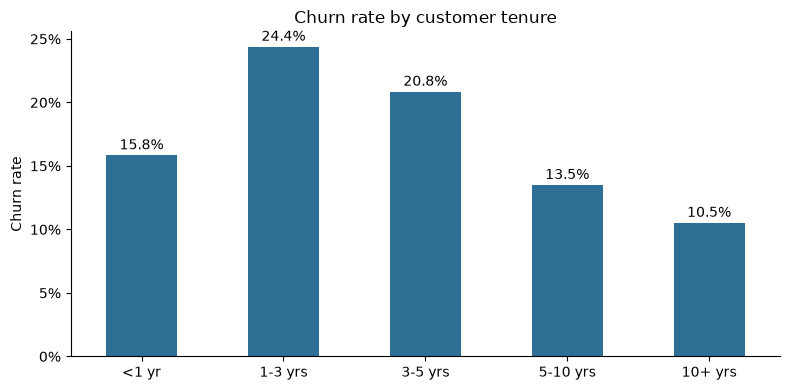

,terms,churn_rate
tenure_band,,
<1 yr,41298,0.16
1-3 yrs,17282,0.24
3-5 yrs,13439,0.21
5-10 yrs,20978,0.13
10+ yrs,7002,0.11


In [7]:
tenure = churn_by(df, 'tenure_band')
bar(tenure['churn_rate'], 'Churn rate by customer tenure', '04_tenure.png')
tenure

## 4.5 Q5: Are higher premiums linked to cancellation?

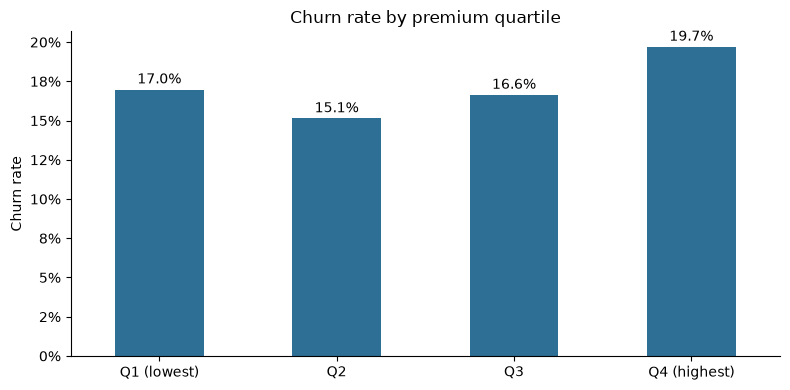

,terms,churn_rate,premium_range
premium_quartile,,,
Q1 (lowest),25006,0.17,"$0 - $1,042"
Q2,25013,0.15,"$1,042 - $1,662"
Q3,24983,0.17,"$1,662 - $2,524"
Q4 (highest),24997,0.20,"$2,524 - $2,874,713"


In [8]:
prem = churn_by(df, 'premium_quartile')
prem['premium_range'] = df.groupby('premium_quartile', observed=True)['Term_Premium'].agg(lambda s: f'${s.min():,.0f} - ${s.max():,.0f}')
bar(prem['churn_rate'], 'Churn rate by premium quartile', '05_premium.png')
prem

## 4.6 Q6: Which provinces and carriers cancel most?

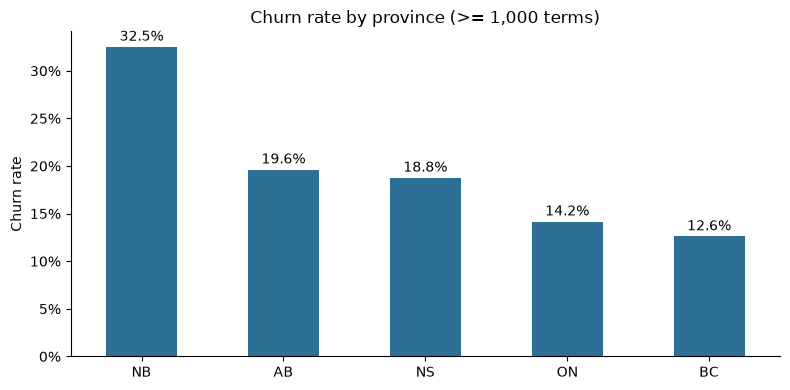

,terms,churn_rate
Province,,
NB,7319,0.33
AB,27301,0.20
NS,2467,0.19
ON,59892,0.14
BC,1729,0.13


In [9]:
prov = churn_by(df, 'Province').query('terms >= 1000').sort_values('churn_rate', ascending=False)
bar(prov['churn_rate'], 'Churn rate by province (>= 1,000 terms)', '06_province.png')
prov

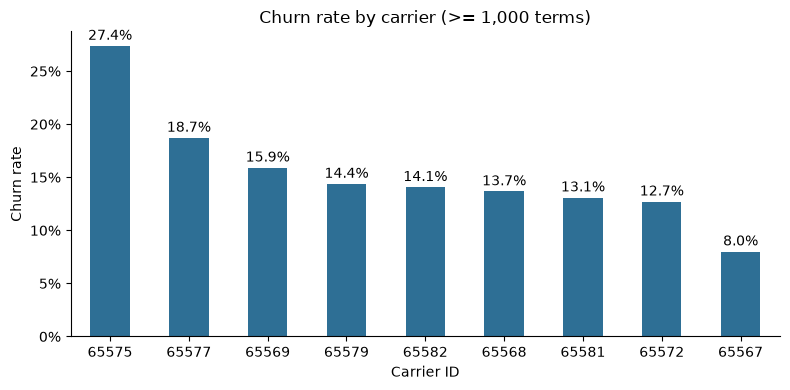

,terms,churn_rate
Carrier_id,,
65575,21505,0.27
65577,16798,0.19
65569,6470,0.16
65579,8472,0.14
65582,9473,0.14
65568,1317,0.14
65581,21876,0.13
65572,1133,0.13
65567,9659,0.08


In [10]:
carrier = churn_by(df, 'Carrier_id').query('terms >= 1000').sort_values('churn_rate', ascending=False)
carrier.index = carrier.index.astype(str)
bar(carrier['churn_rate'], 'Churn rate by carrier (>= 1,000 terms)', '07_carrier.png', xlabel='Carrier ID')
carrier

Province and carrier may overlap: a carrier concentrated in a high-churn province would look worse. The table below compares carriers **within the same province**.

In [11]:
big = df[df['Province'].isin(['ON', 'AB', 'NB']) & df['Carrier_id'].isin(carrier.index.astype(int)[:5])]
pd.crosstab(big['Carrier_id'], big['Province'], values=big['churned'], aggfunc='mean').style.format('{:.1%}', na_rep='-')

Province,AB,NB,ON
Carrier_id,,,
65569,10.8%,27.7%,12.9%
65575,48.3%,49.1%,18.1%
65577,16.6%,13.1%,21.5%
65579,30.8%,50.0%,14.3%
65582,11.5%,16.4%,15.1%


In [12]:
pd.crosstab(big['Carrier_id'], big['Province']).style.format('{:,.0f}')

Province,AB,NB,ON
Carrier_id,,,
65569,"2,159","1,457","2,629"
65575,"2,961","3,342","13,757"
65577,"8,134",647,"7,749"
65579,13,10,"8,441"
65582,"2,504",529,"5,357"


## 4.7 Q7: Auto policies, driver profile

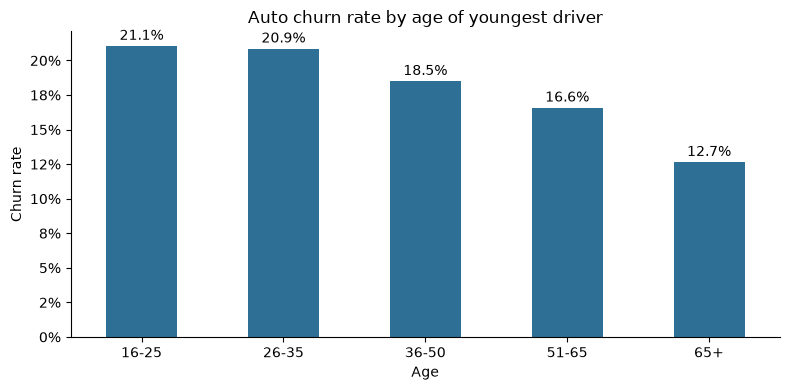

,terms,churn_rate
age_band,,
16-25,1895,0.21
26-35,3078,0.21
36-50,4268,0.19
51-65,3147,0.17
65+,2932,0.13


In [13]:
auto['age_band'] = pd.cut(auto['youngest_driver_age'], [15, 25, 35, 50, 65, 120], labels=['16-25', '26-35', '36-50', '51-65', '65+'])
age = churn_by(auto, 'age_band')
bar(age['churn_rate'], 'Auto churn rate by age of youngest driver', '08_driver_age.png', xlabel='Age')
age

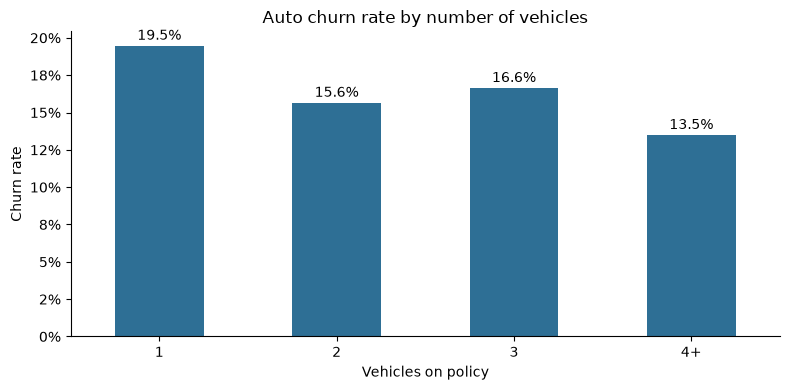

,terms,churn_rate
vehicle_count,,
1,8555,0.19
2,4577,0.16
3,1473,0.17
4+,749,0.13


In [14]:
v = auto.dropna(subset=['vehicles']).copy()
v['vehicle_count'] = v['vehicles'].map(lambda n: '4+' if n >= 4 else str(int(n)))
veh = churn_by(v, 'vehicle_count').sort_index()
bar(veh['churn_rate'], 'Auto churn rate by number of vehicles', '09_vehicles.png', xlabel='Vehicles on policy')
veh

## 4.8 Robustness check: excluding 2025 terms
Terms that started in 2025 may not have reached renewal. Re-running key cuts on 2023 to 2024 terms checks that the findings still hold.

In [15]:
mature = df[df['start_year'] <= 2024]
pd.DataFrame({
    'all terms': [df.churned.mean(), *churn_by(df, 'bundled')['churn_rate'], churn_by(df, 'tenure_band').loc['1-3 yrs', 'churn_rate'], churn_by(df, 'Province').loc['NB', 'churn_rate']],
    '2023-2024 only': [mature.churned.mean(), *churn_by(mature, 'bundled')['churn_rate'], churn_by(mature, 'tenure_band').loc['1-3 yrs', 'churn_rate'], churn_by(mature, 'Province').loc['NB', 'churn_rate']],
}, index=['Overall', 'Bundled', 'Single line', 'Tenure 1-3 yrs', 'New Brunswick']).style.format('{:.1%}')

,all terms,2023-2024 only
Overall,17.1%,20.7%
Bundled,14.7%,17.3%
Single line,17.9%,21.9%
Tenure 1-3 yrs,24.4%,27.3%
New Brunswick,32.5%,38.5%


## 4.9 Segment priority matrix
Size of segment combined with its churn rate shows where retention effort pays off most.

In [16]:
seg = df.groupby(['LOB_Group', 'tenure_band', 'bundled'], observed=True).agg(terms=('churned', 'size'), churn_rate=('churned', 'mean'), lost_terms=('churned', 'sum'))
seg.sort_values('lost_terms', ascending=False).head(8).style.format({'churn_rate': '{:.1%}', 'terms': '{:,.0f}', 'lost_terms': '{:,.0f}'})

## 4.10 Estimated business impact
What is the priority segment (single-line auto clients with up to 5 years of tenure) worth?
Assumption: a retention programme reduces cancellations in this segment by 10%. Premium outliers are excluded from the average.

In [17]:
prio = df[(df['LOB_Group'] == 'Auto') & (df['bundled'] == 'Single line') & (df['tenure_years'] <= 5)]
lost = prio[prio['churned'] == 1]
avg_prem = lost.loc[~lost['premium_outlier'], 'Term_Premium'].mean()
impact = pd.Series({
    'Terms in segment': len(prio),
    'Cancelled terms': len(lost),
    'Share of all cancellations': len(lost) / df['churned'].sum(),
    'Average premium of a cancelled term': avg_prem,
    'Terms kept at 10% reduction': len(lost) * 0.10,
    'Premium kept at 10% reduction': len(lost) * 0.10 * avg_prem,
})
impact.to_frame('value').style.format(lambda v: f'{v:.1%}' if v < 1 else f'{v:,.0f}')

,value
Terms in segment,"33,028"
Cancelled terms,"6,817"
Share of all cancellations,39.8%
Average premium of a cancelled term,"2,686"
Terms kept at 10% reduction,682
Premium kept at 10% reduction,"1,830,864"


## 4.11 Where does the carrier problem come from?
Carrier 65575 looked worst overall. Splitting its cancellations into renewal and mid-term, and comparing with other carriers in the same province, shows what kind of problem it is.

In [18]:
rows = []
for prov in ['AB', 'NB', 'ON']:
    d = df[df['Province'] == prov]
    for name, g in [('Carrier 65575', d[d['Carrier_id'] == 65575]), ('Other carriers', d[d['Carrier_id'] != 65575])]:
        rows.append((prov, name, len(g), g['CAN_REN'].mean(), g['CAN_MT'].mean(), g['churned'].mean()))
pd.DataFrame(rows, columns=['Province', 'Group', 'terms', 'renewal_cancel', 'midterm_cancel', 'churn']).style.format(
    {'terms': '{:,.0f}', 'renewal_cancel': '{:.1%}', 'midterm_cancel': '{:.1%}', 'churn': '{:.1%}'})

,Province,Group,terms,renewal_cancel,midterm_cancel,churn
0,AB,Carrier 65575,"2,961",38.7%,9.6%,48.3%
1,AB,Other carriers,"24,340",8.7%,7.4%,16.1%
2,NB,Carrier 65575,"3,342",42.5%,6.6%,49.1%
3,NB,Other carriers,"3,977",11.5%,7.1%,18.6%
4,ON,Carrier 65575,"13,757",13.0%,5.1%,18.1%
5,ON,Other carriers,"46,135",7.3%,5.7%,13.0%


The gap is almost entirely at **renewal** (about 40% vs 9 to 12% for other carriers), while mid-term cancellation is similar.
That pattern points to renewal pricing or underwriting at this carrier in Alberta and New Brunswick.
Without this carrier, New Brunswick churn falls from 32.5% to 18.6%, so the provincial problem is mostly a carrier problem.

## 4.12 Sizing the recommendations
Each lever gets an explicit, conservative assumption. Premium outliers are excluded from average premiums.
The levers overlap (for example, some carrier 65575 clients are also early-tenure auto clients), so the totals are **not additive**.

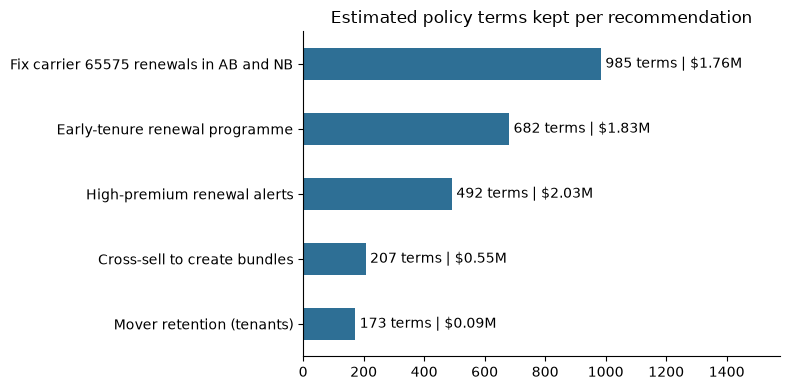

,Assumption,terms_saved,premium_kept
Recommendation,,,
Fix carrier 65575 renewals in AB and NB,Close half the gap to other carriers,985,"$1,757,366"
Early-tenure renewal programme,10% fewer cancellations in segment,682,"$1,830,864"
High-premium renewal alerts,10% fewer cancellations in top quartile,492,"$2,027,937"
Cross-sell to create bundles,10% of single-line auto clients bundle,207,"$551,182"
Mover retention (tenants),20% fewer mid-term cancellations,173,"$92,089"


In [19]:
def lost_prem(d):
    return d.loc[(d['churned'] == 1) & ~d['premium_outlier'], 'Term_Premium'].mean()

levers = []
# 1. carrier 65575 in AB and NB: close half the gap to other carriers in the same province
saved_terms = saved_prem = 0
for prov in ['AB', 'NB']:
    d = df[df['Province'] == prov]; c = d[d['Carrier_id'] == 65575]
    excess = len(c) * (c['churned'].mean() - d.loc[d['Carrier_id'] != 65575, 'churned'].mean())
    saved_terms += excess * 0.5; saved_prem += excess * 0.5 * lost_prem(c)
levers.append(('Fix carrier 65575 renewals in AB and NB', 'Close half the gap to other carriers', saved_terms, saved_prem))

# 2. early-tenure retention programme for single-line auto clients
seg = df[(df['LOB_Group'] == 'Auto') & (df['bundled'] == 'Single line') & (df['tenure_years'] <= 5)]
levers.append(('Early-tenure renewal programme', '10% fewer cancellations in segment', seg['churned'].sum() * 0.10, seg['churned'].sum() * 0.10 * lost_prem(seg)))

# 3. renewal price alerts for the top premium quartile
q4 = df[df['premium_quartile'] == 'Q4 (highest)']
levers.append(('High-premium renewal alerts', '10% fewer cancellations in top quartile', q4['churned'].sum() * 0.10, q4['churned'].sum() * 0.10 * lost_prem(q4)))

# 4. bundling: 10% of single-line auto terms move to the bundled churn rate
sa = df[(df['LOB_Group'] == 'Auto') & (df['bundled'] == 'Single line')]
gap = sa['churned'].mean() - df[(df['LOB_Group'] == 'Auto') & (df['bundled'] != 'Single line')]['churned'].mean()
levers.append(('Cross-sell to create bundles', '10% of single-line auto clients bundle', len(sa) * 0.10 * gap, len(sa) * 0.10 * gap * lost_prem(sa)))

# 5. movers: tenant and rented-dwelling mid-term cancellations
mv = df[df['Line_of_Business'].isin(['TPAC', 'RDWL'])]
mv_prem = mv.loc[(mv['CAN_MT'] == 1) & ~mv['premium_outlier'], 'Term_Premium'].mean()
levers.append(('Mover retention (tenants)', '20% fewer mid-term cancellations', mv['CAN_MT'].sum() * 0.20, mv['CAN_MT'].sum() * 0.20 * mv_prem))

impact = pd.DataFrame(levers, columns=['Recommendation', 'Assumption', 'terms_saved', 'premium_kept']).set_index('Recommendation')
ax = impact['terms_saved'].sort_values().plot.barh(color=COLOR, title='Estimated policy terms kept per recommendation')
ax.bar_label(ax.containers[0], labels=[f'{t:,.0f} terms | ${p / 1e6:.2f}M' for t, p in impact.sort_values('terms_saved')[['terms_saved', 'premium_kept']].values], padding=3)
ax.set_xlim(0, impact['terms_saved'].max() * 1.6); ax.set_ylabel('')
save('10_recommendation_impact.png')
impact.style.format({'terms_saved': '{:,.0f}', 'premium_kept': '${:,.0f}'})

## 4.13 Key insights

| # | Insight | Evidence |
|---|---|---|
| 1 | **Churn happens mostly at renewal.** | 10.8% of terms cancel at renewal vs 6.3% mid-term. |
| 2 | **One carrier's renewals are the biggest single leak.** | Carrier 65575 loses 48 to 49% of terms in Alberta and New Brunswick, almost all at renewal, vs 16 to 19% for other carriers there. In Ontario it is also above other carriers (18.1% vs 13.0%), but far less extreme. |
| 3 | **New Brunswick's problem is mainly that carrier.** | NB churn falls from 32.5% to 18.6% without carrier 65575. |
| 4 | **The riskiest years are 1 to 5.** | Churn is 24.4% at 1 to 3 years of tenure and 20.8% at 3 to 5 years, vs 10.5% after 10 years. |
| 5 | **Single-line auto clients in their first 5 years are 40% of all cancellations.** | 6,817 of 17,115 cancelled terms. |
| 6 | **Bundled clients stay longer.** | Auto churn is 14.4% for bundled clients vs 19.0% for auto-only clients. |
| 7 | **High-premium clients shop around.** | The top premium quartile churns at 19.7% vs 16.3% for the rest. |
| 8 | **Tenants cancel mid-term when they move.** | Tenant packages and rented dwellings have the highest mid-term cancellation (11 to 12%). |
| 9 | **Young-driver households churn more.** | About 21% when the youngest driver is under 36, vs 12.7% when all drivers are 65+. |

## 4.14 Recommendations to reduce churn (prioritised)

| Priority | Recommendation | What to do | Est. terms kept | Effort | Timeline |
|---|---|---|---|---|---|
| 1 | **Fix carrier 65575 renewals in AB and NB** | Review its renewal rate increases with the carrier; before each renewal, re-quote at-risk clients with other carriers and move them if cheaper | ~985 | Low | 0 to 3 months |
| 2 | **Early-tenure renewal programme** | 45 days before the 2nd to 5th renewal, call single-line auto clients for a coverage and price review | ~680 | Medium | Pilot 0 to 3, scale 3 to 6 months |
| 3 | **High-premium renewal alerts** | Flag top-quartile policies with large renewal increases and contact them before the renewal notice arrives | ~490 | Medium | 3 to 6 months |
| 4 | **Cross-sell to create bundles** | Offer home or tenant cover with a multi-line discount to auto-only clients, starting with young-driver households | ~205 | Medium | 3 to 12 months |
| 5 | **Mover retention for tenants** | When a tenant reports a move, transfer the policy to the new address; offer a home policy when they buy | ~170 | Low | 0 to 3 months |

Added up, the five levers keep about **2,500 policy terms and $6.3M in premium** over a comparable period. The levers overlap, so the realistic combined effect is lower than this sum.

## 4.15 How to measure success
- **Pilot with a control group:** run the early-tenure programme on a random half of the target segment first, and compare churn with the untouched half to prove the effect.
- **KPIs:** renewal retention rate (overall, by tenure band and by carrier and province), share of bundled clients, mid-term cancellation rate for tenants.
- **Monthly churn dashboard** using the definitions in this project, so the team can see whether each lever is working.

## 4.16 Limitations
- Terms that started in 2025 have not all reached renewal, so overall churn is understated; the robustness check shows the findings hold on 2023 to 2024 terms.
- The analysis is descriptive. Differences are associations, not proven causes, which is why the pilot with a control group matters.
- Impact estimates rely on stated assumptions and are premium kept, not profit.
- Driver data covers only 27% of auto terms. Renewal price changes, claims and service data were not available, and are likely churn drivers.
